# Prueba Intertrimestral

**Nombre:**  Paula
**Apellidos:**  Collado de la Peña

**Tiempo de la prueba:** 2 horas  
**Asignatura:** Desarrollo de Aplicaciones para la Visualización de Datos  
**Fecha:** 19 de octubre de 2027  

## Instrucciones

- Escribe **código limpio y autoexplicativo**.  
- Se pueden utilizar **los materiales de clase**.  
- Se puede utilizar **internet** para búsqueda de dudas y documentación.  
- **No se puede utilizar ningún tipo de LLM** (ChatGPT, Copilot, Gemini, etc.).  
- **No se puede utilizar mensajería instantánea**.  
- Al finalizar, **sube tu notebook a GitHub** y envía el enlace del fichero según las instrucciones del profesor.

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**

## Dataset “City Micromobility Hourly”

El fichero `city_micromobility_hourly.csv` contiene **alquileres horarios** de bicicletas y patinetes compartidos en una ciudad (ene 2025 – dic 2026): meteorología, tipo de día, usuarios ocasionales/abonados, duración media, ingresos y una etiqueta de alta demanda.

Hay un `.txt` con la descripción de las variables en la misma carpeta.


## Inicialización de librerías


In [2]:
import pandas as pd
import numpy as np
import sklearn.datasets
import seaborn as sns
from scipy.stats import ttest_ind
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from itertools import combinations
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    classification_report,
    confusion_matrix
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier, LogisticRegression

# Ejercicio 1 — Programación (2 puntos)

a) (0.6 pts) Crea una función `rental_fee(duration_min, bike_type, is_member)` que calcule la tarifa de un viaje en euros, redondeada a **dos decimales**, con estas reglas:

- Tarifa base: **1.00 €** si `bike_type == "classic"`, **1.50 €** si `bike_type == "electric"`.
- Coste por minuto: **0.05 €/min** (classic) o **0.08 €/min** (electric).
- Si `is_member` es `True`, aplica un **20 % de descuento** sobre el total.
- Si `bike_type` no es `"classic"` ni `"electric"`, lanza `ValueError`.

Ejemplo orientativo: `rental_fee(20, "classic", False)` → `2.00`.


In [12]:
def rental_fee(duration_min, bike_type, is_member):
    if bike_type=="classic":
        tarifa_base = 1
        coste_minuto = 0.05
    elif bike_type == "electric":
        tarifa_base = 1.5
        coste_minuto = 0.08
    else:
        raise ValueError("Bike type no correcto")

    total = tarifa_base + duration_min * coste_minuto

    if is_member:
        total = 0.80 * total

    return round(total,2)

print(rental_fee(20, "classic", False))

2.0


b) (0.6 pts) Crea una función `demand_label(total_rentals, threshold)` que devuelva `"Alta"` si `total_rentals >= threshold`, `"Media"` si está entre `threshold/2` (incluido) y `threshold` (excluido), y `"Baja"` en caso contrario.


In [49]:
def demand_label(total_rentals, threshold):
    if total_rentals>= threshold:
        return "Alta"
    elif total_rentals>=threshold/2:
        return "Media"
    else:
        return "Baja"

print(demand_label(2, 0.36))

Alta


c) (0.6 pts) Genera un DataFrame llamado `tripsDemo` con **al menos 10 filas** y columnas:

- `duration_min` (float)
- `bike_type` (`"classic"` o `"electric"`)
- `is_member` (bool)
- `fee` (calculada con `rental_fee`)
- `total_rentals` (int, inventado)
- `demand` (calculada con `demand_label`, usando por ejemplo `threshold=40`)

Muestra el DataFrame completo.


In [33]:
# Datos Ejemplo
datos = {
    "duration_min": [20.0, 35.0, 15.0, 45.0, 10.0,
                     30.0, 25.0, 50.0, 12.0, 40.0],
    "bike_type": ["classic", "electric", "classic", "electric", "classic",
                  "electric", "classic", "electric", "classic", "electric"],
    "is_member": [True, False, True, True, False,
                  True, False, False, True, False],
    "total_rentals": [50, 30, 20, 60, 10,
                      45, 35, 15, 80, 40]
}

tripsDemo = pd.DataFrame(datos)

tripsDemo["fee"] = tripsDemo.apply(
    lambda fila: rental_fee(
        fila["duration_min"],
        fila["bike_type"],
        fila["is_member"]
    ),
    axis=1
)

tripsDemo["demand"] = tripsDemo["total_rentals"].apply(
    lambda x: demand_label(x, 40)
)

print(tripsDemo.to_string(index=False))

 duration_min bike_type  is_member  total_rentals  fee demand
         20.0   classic       True             50 1.60   Alta
         35.0  electric      False             30 4.30  Media
         15.0   classic       True             20 1.40  Media
         45.0  electric       True             60 4.08   Alta
         10.0   classic      False             10 1.50   Baja
         30.0  electric       True             45 3.12   Alta
         25.0   classic      False             35 2.25  Media
         50.0  electric      False             15 5.50   Baja
         12.0   classic       True             80 1.28   Alta
         40.0  electric      False             40 4.70   Alta


d) (0.2 pts) Integra ambas funciones en una clase `MicromobilityTools` que, a partir de listas/arrays de `duration_min`, `bike_type` e `is_member`, calcule las tarifas y (opcionalmente) etiquete demanda a partir de una lista de `total_rentals` y un `threshold`.


In [123]:
class MicromobilityTools:

    def __init__(self, duration_min, bike_type, is_member, total_rentals=None, threshold=40):
        self.duration_min = duration_min
        self.bike_type = bike_type
        self.is_member = is_member
        self.total_rentals = total_rentals
        self.threshold = threshold

    def calcular_tarifas(self):
        tarifas = []

        for i in range(len(self.duration_min)):
            tarifa = rental_fee(
                self.duration_min[i],
                self.bike_type[i],
                self.is_member[i]
            )
            tarifas.append(tarifa)

        return tarifas

    def etiquetar_demanda(self):
        if self.total_rentals is None:
            return None

        demandas = []

        for i in range(len(self.total_rentals)):
            demanda = demand_label(
                self.total_rentals[i],
                self.threshold
            )
            demandas.append(demanda)

        return demandas

In [124]:
#Prueba clase 
tools = MicromobilityTools(
    duration_min=[20, 35, 15],
    bike_type=["classic", "electric", "classic"],
    is_member=[True, False, True],
    total_rentals=[50, 30, 20],
    threshold=40
)

print(tools.calcular_tarifas())
print(tools.etiquetar_demanda())

[1.6, 4.3, 1.4]
['Alta', 'Media', 'Media']


## Ejercicio 2 — Exploración y visualización (3 puntos)

a) (0.75 pts) Carga `city_micromobility_hourly.csv` en un DataFrame `mobilityData`. Muestra las 5 primeras filas y el número de filas y columnas.


In [87]:
mobilityData= pd.read_csv("city_micromobility_hourly.csv")

print(mobilityData.head(5))
print("Número de filas y columnas:", mobilityData.shape)

              datetime  year  month  day  hour  weekday  season  is_holiday  \
0  2025-01-01 00:00:00  2025      1    1     0        2  Winter           1   
1  2025-01-01 01:00:00  2025      1    1     1        2  Winter           1   
2  2025-01-01 02:00:00  2025      1    1     2        2  Winter           1   
3  2025-01-01 03:00:00  2025      1    1     3        2  Winter           1   
4  2025-01-01 04:00:00  2025      1    1     4        2  Winter           1   

   is_weekend  is_workingday  ... wind_kmh  precip_mm  casual_users  \
0           0              0  ...      9.7        0.0             2   
1           0              0  ...      2.8        0.0             1   
2           0              0  ...      9.0        0.0             1   
3           0              0  ...      5.4        0.0             2   
4           0              0  ...      2.4        0.0             1   

   member_users  total_rentals  avg_trip_min  avg_distance_km  electric_share  \
0             8  

b) (0.75 pts) Crea una función `describeData(dataFrame)` que, para cada columna, devuelva: tipo de dato, número de nulos y porcentaje de nulos.


In [90]:
def describeData(dataFrame):
    resumen = pd.DataFrame({
        "tipo_dato": dataFrame.dtypes,
        "nulos": dataFrame.isnull().sum(),
        "porcentaje_nulos": dataFrame.isnull().mean() * 100
    })

    return resumen

c) (0.75 pts) Usa `describeData(mobilityData)` y comenta brevemente (2–3 líneas) qué variables tienen más valores faltantes y qué harías con ellas antes de modelar.


In [97]:
print(describeData(mobilityData).to_string())

                tipo_dato  nulos  porcentaje_nulos
datetime              str      0          0.000000
year                int64      0          0.000000
month               int64      0          0.000000
day                 int64      0          0.000000
hour                int64      0          0.000000
weekday             int64      0          0.000000
season                str      0          0.000000
is_holiday          int64      0          0.000000
is_weekend          int64      0          0.000000
is_workingday       int64      0          0.000000
weather               str      0          0.000000
temp_c            float64      0          0.000000
humidity          float64    224          1.278539
wind_kmh          float64    142          0.810502
precip_mm         float64      0          0.000000
casual_users        int64      0          0.000000
member_users        int64      0          0.000000
total_rentals       int64      0          0.000000
avg_trip_min      float64    25

Las variables con más valores faltantes son avg_trip_min (1,46 %), humidity (1,28 %), electric_share (1,04 %) y wind_kmh (0,81 %). Antes de modelar, analizaría los valores ausentes y como su porcentaje es bajo, los imputaría con la mediana para las variables numéricas, evitando asi perder datos.

d) (0.75 pts) Elabora **dos** visualizaciones:

1. Un gráfico de correlación entre variables numéricas relevantes (por ejemplo `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `casual_users`, `member_users`, `total_rentals`, `revenue_eur`).
2. Un gráfico que muestre la demanda media (`total_rentals`) por `hour` (y, si quieres, separando fin de semana / laborable).

Comenta 2–3 hallazgos (correlaciones, horas punta, efecto del clima, etc.).


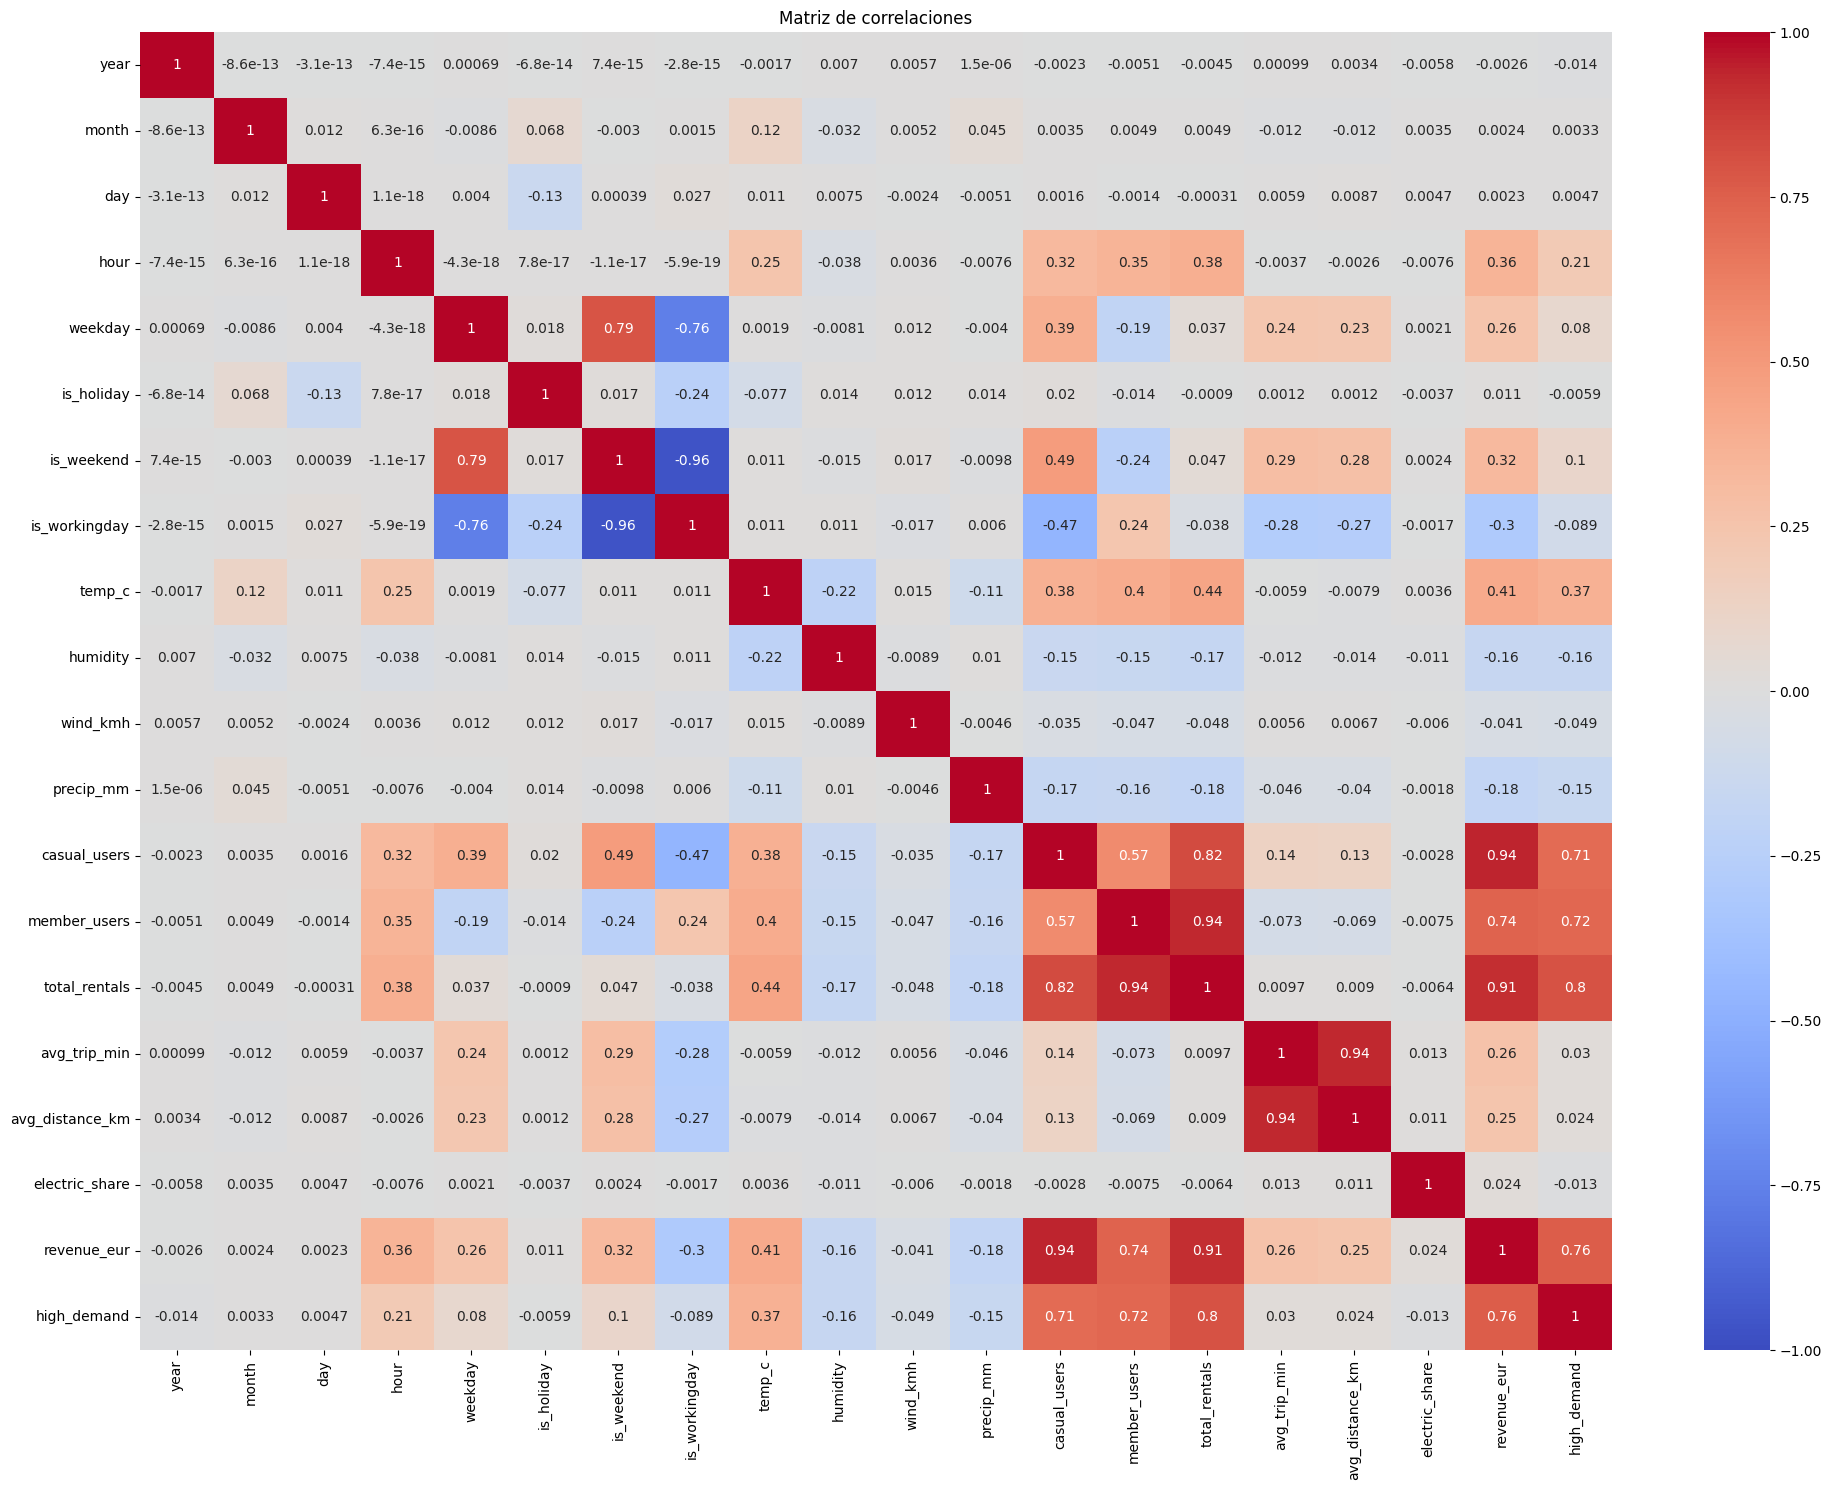

In [107]:
df_numerico = mobilityData.select_dtypes(include="number")
correlaciones = df_numerico.corr()

plt.figure(figsize=(20, 15))

sns.heatmap(correlaciones, annot=True, cmap="coolwarm", vmin=-1, vmax=1)

plt.title("Matriz de correlaciones")
plt.tight_layout()
plt.show()

Existe una correlación positiva muy fuerte entre member_users y total_rentals (0,94), así como entre casual_users y total_rentals (0,82). Esto indica que ambos grupos de usuarios están muy relacionados con el número total de alquileres.
La temperatura (temp_c) presenta una correlación positiva moderada con total_rentals (0,44), mientras que la precipitación (precip_mm) muestra una correlación negativa débil (-0,18). Esto sugiere que las temperaturas más altas se asocian con una mayor demanda y que la lluvia podría relacionarse con una menor demanda.
La variable high_demand presenta una correlación positiva fuerte con total_rentals (0,80). Además, las variables temporales permiten estudiar cómo cambia la demanda a lo largo del día y entre días laborables y fines de semana.

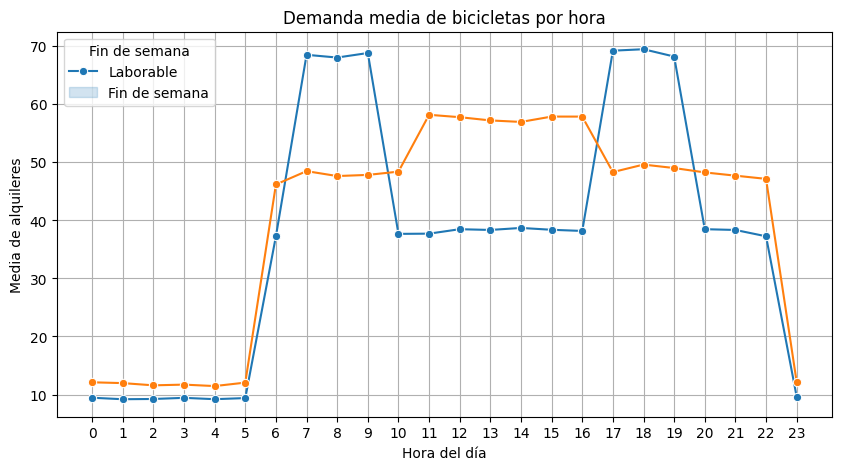

In [112]:
demanda_hora = mobilityData.groupby(["hour", "is_weekend"])["total_rentals"].mean().reset_index()

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=demanda_hora,
    x="hour",
    y="total_rentals",
    hue="is_weekend",
    marker="o"
)

plt.title("Demanda media de bicicletas por hora")
plt.xlabel("Hora del día")
plt.ylabel("Media de alquileres")
plt.xticks(range(24))
plt.legend(title="Fin de semana", labels=["Laborable", "Fin de semana"])
plt.grid(True)
plt.show()

Correlaciones: member_users presenta una correlación positiva muy fuerte con total_rentals (0,94), mientras que temp_c tiene una correlación positiva moderada (0,44) y precip_mm una correlación negativa débil (-0,18).
Horas punta: en los días laborables se observan dos picos de demanda, entre las 7:00 y las 9:00 y entre las 17:00 y las 19:00, con una media cercana a 70 alquileres. Estos picos podrían estar relacionados con los desplazamientos al trabajo y el regreso a casa.
Diferencias entre días: durante los fines de semana, la demanda se mantiene relativamente estable entre las 11:00 y las 16:00, con unos 57–58 alquileres de media. Esto contrasta con los picos de los días laborables y podría reflejar patrones de uso diferentes.

## Ejercicio 3 — Regresión (2 puntos)

Queremos predecir `total_rentals`.

a) (0.25 pts) Define `targetVar = "total_rentals"` y selecciona **3–5** variables predictoras numéricas razonables (p. ej. `hour`, `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `is_workingday`, `is_weekend`). Construye `X` e `y`, tratando nulos de forma simple (p. ej. eliminar filas o imputar la mediana).


In [125]:
# Definir la variable objetivo
targetVar = "total_rentals"

# Seleccionar las variables predictoras
predictors = ["hour", "temp_c", "humidity"]

# Crear X e y
X = mobilityData[predictors]
y = mobilityData[targetVar]

# COMPROBAR Y ELIMINAR VALORES NULOS
print("Valores nulos en X:", X.isnull().sum().sum())
print("Valores nulos en y:", y.isnull().sum())

# Unir X e y y eliminar las filas con valores nulos
datos = pd.concat([X, y], axis=1).dropna()

# Volver a separar X e y
X = datos[predictors]
y = datos[targetVar]

print("Variables predictoras:")
print(X.head())

print("\nVariable objetivo:")
print(y.head())

print("\nDimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Valores nulos en X: 224
Valores nulos en y: 0
Variables predictoras:
   hour  temp_c  humidity
0     0    6.39      67.1
1     1    4.88      37.2
2     2    1.72      79.7
3     3   -3.40      51.4
4     4    8.24      82.2

Variable objetivo:
0    10
1     6
2     5
3    12
4     5
Name: total_rentals, dtype: int64

Dimensiones de X: (17296, 3)
Dimensiones de y: (17296,)


b) (0.25 pts) Divide en entrenamiento (70 %) y prueba (30 %) con `random_state=42`.


In [126]:
# Dividir los datos
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

Datos de entrenamiento: (12107, 3)
Datos de prueba: (5189, 3)


c) (0.75 pts) Entrena un `LinearRegression`, calcula **R²** y **MSE** en el conjunto de prueba y comenta el resultado en 1–2 líneas.


In [127]:
from sklearn.linear_model import LinearRegression

# Crear el modelo
modelo_lr = LinearRegression()

# Entrenar
modelo_lr.fit(X_train, y_train)

# Realizar predicciones
y_pred_lr = modelo_lr.predict(X_test)

print("Predicciones:", y_pred_lr[:10])
print("Valores reales:", y_test[:10].values)

# Calcular las métricas
r2_lr = r2_score(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)

# Mostrar resultados
print("R² Regresion Lineal:", r2_lr)
print("MSE Regresion Lineal:", mse_lr)

Predicciones: [25.7984851  39.17406937 43.04764217 31.48064118 19.8713715  22.95263986
 24.385195   43.84007281 41.81782481 27.02945649]
Valores reales: [52  9 46 54 50 10  5 84 41 10]
R² Regresion Lineal: 0.2993049145197366
MSE Regresion Lineal: 415.71136906244254


El modelo de regresión lineal obtiene un R² de 0,2993, por lo que explica aproximadamente el 29,93 % de la variabilidad de total_rentals. El MSE es 415,71, lo que indica que todavía existen errores considerables entre las predicciones y los valores reales, por lo que el modelo podría mejorarse incorporando otras variables relevantes.

d) (0.75 pts) Entrena un `RandomForestRegressor` (mismo split) y compara R² y MSE con la regresión lineal. ¿Cuál funciona mejor y por qué crees que es así?


In [63]:
# Crear el modelo
modelo_rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Entrenar
modelo_rf.fit(X_train, y_train)

# Predecir
y_pred_rf = modelo_rf.predict(X_test)

# Evaluar
r2_rf = r2_score(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)

print("R² Random Forest:", r2_rf)
print("MSE Random Forest:", mse_rf)

R² Random Forest: 0.7368195720255559
MSE Random Forest: 156.1408068799383


## Comparacion

El modelo Random Forest obtiene un R² de 0,7368 y un MSE de 156,14, mejorando los resultados de la regresión lineal (R² = 0,2993 y MSE = 415,71). Por tanto, Random Forest funciona mejor, ya que explica una mayor proporción de la variabilidad de los alquileres y comete menores errores de predicción. Esto puede deberse a que captura relaciones no lineales e interacciones entre las variables predictoras que la regresión lineal no representa adecuadamente.

## Ejercicio 4 — Clasificación (2 puntos)

Usa la columna `high_demand` (1 = demanda alta, 0 = no).

a) (0.25 pts) Comprueba el balance de clases (`value_counts` o proporción) de `high_demand`.


In [113]:
# Contar los registros de cada clase
print(mobilityData["high_demand"].value_counts())

# Calcular el porcentaje de cada clase
print(mobilityData["high_demand"].value_counts(normalize=True) * 100)

high_demand
0    12071
1     5449
Name: count, dtype: int64
high_demand
0    68.898402
1    31.101598
Name: proportion, dtype: float64


b) (0.75 pts) Entrena un `LogisticRegression` para predecir `high_demand` usando variables de contexto (hora, clima, tipo de día, etc.). Recuerda preparar `X`/`y` y el split train/test.


In [117]:
targetVar = "high_demand"

predictors = ["hour", "temp_c", "humidity"]

X = mobilityData[predictors]
y = mobilityData[targetVar]

# COMPROBAR Y ELIMINAR VALORES NULOS
print("Valores nulos en X:", X.isnull().sum().sum())
print("Valores nulos en y:", y.isnull().sum())

# Unir X e y y eliminar las filas con valores nulos
datos = pd.concat([X, y], axis=1).dropna()

# Volver a separar X e y
X = datos[predictors]
y = datos[targetVar]

print("Variables predictoras:")
print(X.head())

print("\nVariable objetivo:")
print(y.head())

print("\nDimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

modelo_log = LogisticRegression(max_iter=1000)

modelo_log.fit(X_train, y_train)

y_pred_log = modelo_log.predict(X_test)

Valores nulos en X: 224
Valores nulos en y: 0
Variables predictoras:
   hour  temp_c  humidity
0     0    6.39      67.1
1     1    4.88      37.2
2     2    1.72      79.7
3     3   -3.40      51.4
4     4    8.24      82.2

Variable objetivo:
0    0
1    0
2    0
3    0
4    0
Name: high_demand, dtype: int64

Dimensiones de X: (17296, 3)
Dimensiones de y: (17296,)


c) (0.25 pts) Calcula la **accuracy** y muestra la **matriz de confusión**.


Accuracy: 0.744074002698015
[[3276  299]
 [1029  585]]


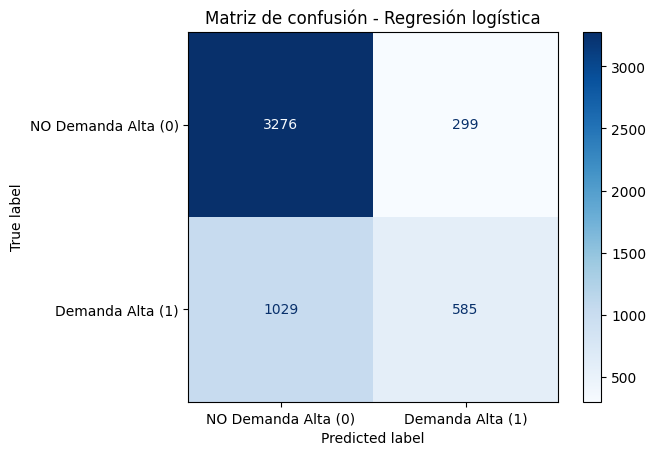

In [118]:
accuracy = accuracy_score(y_test, y_pred_log)

print("Accuracy:", accuracy)

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_log)

print(cm)

# Representar la matriz de confusión
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NO Demanda Alta (0)", "Demanda Alta (1)"]
)

disp.plot(cmap="Blues")
plt.title("Matriz de confusión - Regresión logística")
plt.show()

d) (0.75 pts) Interpreta qué factores parecen asociarse más a la alta demanda (coeficientes del modelo logístico y/o importancia si usas un árbol; o argumentación basada en tus gráficos del ejercicio 2).


In [121]:
coeficientes = pd.DataFrame({
    "Variable": X.columns,
    "Coeficiente": modelo_log.coef_[0]
})

print(coeficientes)

   Variable  Coeficiente
0      hour     0.046827
1    temp_c     0.094422
2  humidity    -0.015417


Los coeficientes de la regresión logística muestran que la temperatura (temp_c) tiene una asociación positiva con la demanda alta, con un coeficiente de 0,0944. La hora (hour) también presenta una asociación positiva, con un coeficiente de 0,0468. En cambio, la humedad (humidity) tiene una asociación negativa, con un coeficiente de -0,0154. Por tanto según el modelo una mayor temperatura y una hora más avanzada se asocian con una mayor probabilidad estimada de demanda alta, mientras que una mayor humedad se asocia con una menor probabilidad.

## Ejercicio 5 — Conclusión (1 punto)

En un máximo de **300 palabras**, resume:

* Qué factores (hora, clima, tipo de día, etc.) parecen mover más la demanda de micromovilidad.  
* Qué modelo predictivo te ha funcionado mejor y por qué.  
* Qué mejorarías con más tiempo o datos (más ciudades, eventos, precio dinámico, etc.).


Al finalizar:

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**



El análisis de los datos muestra que la demanda de micromovilidad está relacionada con la hora del día y las condiciones meteorológicas. En los días laborables se observan dos picos de demanda, por la mañana (7:00-9:00) y por la tarde (17:00-19:00), posiblemente relacionados con los desplazamientos al trabajo o al centro de estudios. Durante los fines de semana, la demanda se mantiene más estable en las horas centrales del día. Además, la temperatura presenta una correlación positiva moderada con el número de alquileres (0,44), mientras que la precipitación tiene una correlación negativa débil (-0,18). En la regresión logística, la temperatura y la hora presentan coeficientes positivos, mientras que la humedad tiene un coeficiente negativo.

En cuanto a los modelos predictivos, el Random Forest ha funcionado mejor que la regresión lineal para predecir el número de alquileres. Ha obtenido un R² de 0,737 y un error cuadrático medio (MSE) de 156,14, frente al R² de 0,299 y el MSE de 415,71 de la regresión lineal. Esto indica que Random Forest explica una mayor parte de la variabilidad de la demanda y comete errores de predicción menores. Para clasificar la demanda alta, la regresión logística ha obtenido una accuracy del 74,41 %, aunque presenta dificultades para detectar algunos periodos de demanda alta.

Con más tiempo, mejoraría los modelos incorporando más variables, como eventos locales, festivos y disponibilidad de bicicletas. También sería interesante analizar datos de varias ciudades y utilizar validación temporal para evaluar mejor las predicciones sobre periodos futuros. 